# Decision trees and random forests

*Data Science and AI, Module 7 Part 1. Slides: `Module_7_Part_1.pdf`.*

Keep the slides open on the right. Every heading below carries the slide
numbers it goes with, so the two stay in step. The maths at the back of the
deck (slides 29-40) is taught where it is first needed, under slide 15.

A decision tree makes a prediction by asking a short chain of yes/no
questions: "is the bill deeper than so many millimetres?", then another,
until it reaches an answer. A random forest grows many such trees and
combines their answers.

**How each section works.** A question comes first. Make a guess out loud or
in the chat before the cell runs. Then run it and compare.

**Three kinds of data.**

- The slides' own example: 30 students and cricket. Only the counts printed
  on the slides are used.
- Small **made-up** examples, always labelled as made up.
- One **real** dataset: 344 penguins of three species from three islands
  near Palmer Station, Antarctica. The file is `penguins_size.csv`, in the
  `data/` folder at the top of the repository.

Penguin data: collected and made available by Dr. Kristen Gorman and the
Palmer Station, Antarctica LTER, available under a CC-0 licence in accordance
with the Palmer Station LTER Data Policy. Gorman KB, Williams TD, Fraser WR
(2014), *Ecological sexual dimorphism and environmental variability within a
community of Antarctic penguins (genus Pygoscelis)*, PLoS ONE 9(3): e90081.

# Part 1: slides 1-14

What a decision tree is, how one grows, and where it is strong and weak.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split

print("scikit-learn", sklearn.__version__)

MEASUREMENTS = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]

# Real data: penguins measured at Palmer Station, Antarctica. "Culmen" is the bill.
raw = pd.read_csv("../../../data/penguins_size.csv")

# Two penguins have no measurements at all, so there is nothing to learn from them.
penguins = raw.dropna(subset=MEASUREMENTS, how="all")

# For the male/female questions, keep only rows where sex is recorded properly.
sexed = penguins[penguins["sex"].isin(["MALE", "FEMALE"])]

# Question 1: which species? One fixed split, used all the way through.
X_train, X_test, y_train, y_test = train_test_split(
    penguins[MEASUREMENTS], penguins["species"],
    test_size=0.25, stratify=penguins["species"], random_state=42)

# Question 2: male or female? A harder question, used to show a tree's weak spots.
S_train, S_test, s_train, s_test = train_test_split(
    sexed[MEASUREMENTS], sexed["sex"],
    test_size=0.25, stratify=sexed["sex"], random_state=42)

print("species: learn on", len(X_train), "penguins, test on", len(X_test))
print("sex:     learn on", len(S_train), "penguins, test on", len(S_test))


def gini(proportions):
    """Gini impurity: 1 minus the sum of squared proportions. 0 means pure."""
    total = 1.0
    for p in proportions:
        total = total - p ** 2
    return total


def entropy(proportions):
    """Entropy in bits. 0 means pure; two classes at 50/50 give 1."""
    total = 0.0
    for p in proportions:
        if p > 0:
            total = total - p * math.log2(p)
    return total

scikit-learn 1.9.0
species: learn on 256 penguins, test on 86
sex:     learn on 249 penguins, test on 84


## Slides 1-2: Title and agenda

This part of Module 7 covers decision trees and random forests.

## Slides 3-4: A tree asks one question at a time

A decision tree is a **supervised** method: it learns from examples where
the answer is already known.

It splits the data with one question about one column, then splits each
group again, aiming for groups that are as **pure** as possible, meaning
mostly one answer. It stops when a stop rule is reached (for example, a
maximum number of questions).

The kind of answer decides the kind of tree:

- a **classification tree** predicts a category (which species?);
- a **regression tree** predicts a number (how heavy?).

Before any tree, look at the real data. This is the file exactly as it
arrives.

In [2]:
# What the file looks like before any cleaning
print(raw.shape)
print(raw.head())

(344, 7)
  species     island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen              39.1             18.7              181.0   
1  Adelie  Torgersen              39.5             17.4              186.0   
2  Adelie  Torgersen              40.3             18.0              195.0   
3  Adelie  Torgersen               NaN              NaN                NaN   
4  Adelie  Torgersen              36.7             19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  


"Culmen" is the bill, the top ridge of the beak. From here on the text says
bill; the column names stay as they are in the file.

Real data is rarely tidy. Before I run the next cell, how many gaps would
you guess there are, and in which columns?

In [3]:
# Count the gaps in each column
print(raw.isna().sum())

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


The four measurement columns have the same small number of gaps. The sex
column has more. It also has one more surprise.

In [4]:
# Every value in the sex column, including the gaps
print(raw["sex"].value_counts(dropna=False))

sex
MALE      168
FEMALE    165
NaN        10
.           1
Name: count, dtype: int64


The `"."` is not a valid sex value, so it is treated the same as a gap.

What the set-up cell at the top of this part did about it:

- penguins with **no measurements at all** are dropped, because there is
  nothing to learn from them;
- for the **species** question, every other penguin is kept (sex is not
  used);
- for the **male or female** question, only penguins recorded as `MALE` or
  `FEMALE` are kept.

In [5]:
# Check the cleaning: what is left for each question
print("penguins with measurements:", len(penguins))
print("penguins with a proper sex record:", len(sexed))
print("sex values left:", sorted(sexed["sex"].unique()))
print(penguins["species"].value_counts())

penguins with measurements: 342
penguins with a proper sex record: 333
sex values left: ['FEMALE', 'MALE']
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


## Slides 5-6: The apple tree, written as code

Slide 6 turns the apple picture into a tree of three questions. We do not
have the apple data, so this is not a model we trained. It is the tree from
the slide, written as plain Python, to show that a tree is nothing more than
nested if-questions.

In [ ]:
# The tree on slide 6, written as plain Python questions
def apple_colour(weight, juice):
    if weight > 60:
        if juice > 20:
            return "green"
        if weight > 85:
            return "green"
        return "red"
    return "red"


print(apple_colour(50, 22))   # light apple
print(apple_colour(70, 22))   # heavier and juicy
print(apple_colour(70, 15))   # heavier, not juicy, not very heavy
print(apple_colour(95, 15))   # very heavy

```mermaid
flowchart TD
    A{"weight > 60?"} -->|no| R1["red"]
    A -->|yes| B{"juice > 20?"}
    B -->|yes| G1["green"]
    B -->|no| C{"weight > 85?"}
    C -->|yes| G2["green"]
    C -->|no| R2["red"]
```

Now the same idea on the penguins, but this time the computer chooses the
questions. We allow only two questions deep.

Before I run it: which **one** measurement would you ask about first, to
start separating Adelie, Chinstrap and Gentoo?

In [7]:
# Let scikit-learn grow a tree only two questions deep, then print its questions
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42) # max_depth=2 sets how many questions any one penguin gets asked
small_tree.fit(X_train, y_train)
print(export_text(small_tree, feature_names=MEASUREMENTS, show_weights=True)) # , show_weights=True

|--- flipper_length_mm <= 206.50
|   |--- culmen_length_mm <= 43.35
|   |   |--- weights: [107.00, 4.00, 0.00] class: Adelie
|   |--- culmen_length_mm >  43.35
|   |   |--- weights: [4.00, 42.00, 1.00] class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- culmen_depth_mm <= 17.55
|   |   |--- weights: [0.00, 0.00, 91.00] class: Gentoo
|   |--- culmen_depth_mm >  17.55
|   |   |--- weights: [2.00, 5.00, 0.00] class: Chinstrap



[Text(0.5, 0.8333333333333334, 'flipper_length_mm <= 206.5\ngini = 0.636\nsamples = 256\nvalue = [113, 51, 92]\nclass = Adelie'),
 Text(0.25, 0.5, 'culmen_length_mm <= 43.35\ngini = 0.422\nsamples = 158\nvalue = [111, 46, 1]\nclass = Adelie'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.069\nsamples = 111\nvalue = [107, 4, 0]\nclass = Adelie'),
 Text(0.375, 0.16666666666666666, 'gini = 0.194\nsamples = 47\nvalue = [4, 42, 1]\nclass = Chinstrap'),
 Text(0.75, 0.5, 'culmen_depth_mm <= 17.55\ngini = 0.135\nsamples = 98\nvalue = [2.0, 5.0, 91.0]\nclass = Gentoo'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.0\nsamples = 91\nvalue = [0, 0, 91]\nclass = Gentoo'),
 Text(0.875, 0.16666666666666666, 'gini = 0.408\nsamples = 7\nvalue = [2, 5, 0]\nclass = Chinstrap')]

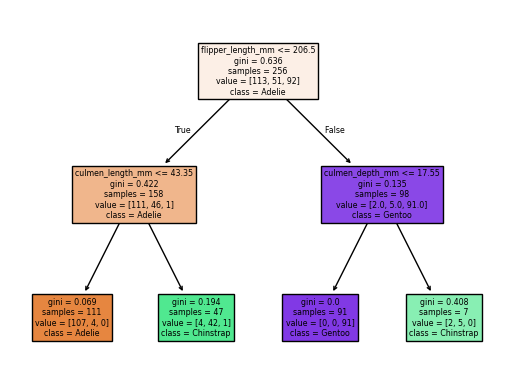

In [8]:
from sklearn.tree import plot_tree
plot_tree(small_tree, feature_names=MEASUREMENTS, class_names=small_tree.classes_, filled=True)

Here is the first question drawn on the data, the same way slide 5 draws its
split lines on the apples.

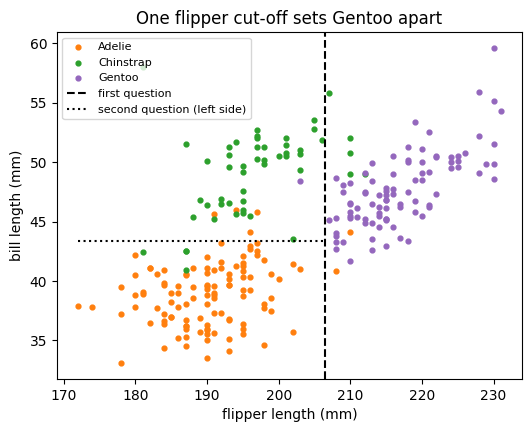

In [9]:
# Flipper length against bill length, one colour per species
# Same colours as the tree drawings below: Adelie orange, Chinstrap green, Gentoo purple
colours = {"Adelie": "tab:orange", "Chinstrap": "tab:green", "Gentoo": "tab:purple"}
plt.figure(figsize=(6, 4.5))
for species_name in colours:
    rows = X_train[y_train == species_name]
    plt.scatter(rows["flipper_length_mm"], rows["culmen_length_mm"], s=12,
                color=colours[species_name], label=species_name)
root_threshold = small_tree.tree_.threshold[0]
plt.axvline(root_threshold, color="black", linestyle="--", label="first question")

# Second question on the left-hand side: bill length (the right-hand side asks about
# bill depth, which is not on this plot)
left_cut = small_tree.tree_.threshold[small_tree.tree_.children_left[0]]
plt.hlines(left_cut, xmin=X_train["flipper_length_mm"].min(), xmax=root_threshold,
           color="black", linestyle=":", label="second question (left side)")
plt.xlabel("flipper length (mm)")
plt.ylabel("bill length (mm)")
plt.title("One flipper cut-off sets Gentoo apart")
plt.legend(loc="upper left", fontsize=8)
plt.show()

Gentoo sit almost alone to the right of the line. On the left, Adelie and
Chinstrap overlap in flipper length, but they differ in bill length, which
is why the tree's second question on that side is about the bill.

In [ ]:
# Step 1: load real data
# Step 2: keep a quarter of the wines aside for testing
# Step 3: grow a small tree on the training wines
# Step 4: read the questions it learned
# Step 5: how often is it right on wines it has never seen?
# Step 6: try different depths and compare train vs test
# Step 7: classify one "new" wine (here, the first test wine)

In [10]:
# Step 1: load real data
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
wine_X = wine.data            # 13 chemical measurements per wine
wine_y = wine.target          # which of 3 growers (cultivars) made it: 0, 1 or 2

print(wine_X.shape)
print(wine_y.value_counts())

# Step 2: keep a quarter of the wines aside for testing
from sklearn.model_selection import train_test_split

wine_X_train, wine_X_test, wine_y_train, wine_y_test = train_test_split(
    wine_X, wine_y, test_size=0.25, stratify=wine_y, random_state=42)

# Step 3: grow a small tree on the training wines
from sklearn.tree import DecisionTreeClassifier, export_text

wine_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
wine_tree.fit(wine_X_train, wine_y_train)

# Step 4: read the questions it learned
print(export_text(wine_tree, feature_names=list(wine_X.columns)))

# Step 5: how often is it right on wines it has never seen?
from sklearn.metrics import accuracy_score, confusion_matrix

wine_predictions = wine_tree.predict(wine_X_test)
print("test accuracy:", round(accuracy_score(wine_y_test, wine_predictions), 3))
print(confusion_matrix(wine_y_test, wine_predictions))

# Step 6: try different depths and compare train vs test
for depth in [1, 2, 3, 5, None]:
    wine_model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    wine_model.fit(wine_X_train, wine_y_train)
    train_acc = wine_model.score(wine_X_train, wine_y_train)
    test_acc = wine_model.score(wine_X_test, wine_y_test)
    print("depth", depth, " train", round(train_acc, 3), " test", round(test_acc, 3))

# Step 7: classify one "new" wine (here, the first test wine)
new_wine = wine_X_test.iloc[[0]]
print("predicted grower:", wine_tree.predict(new_wine)[0])
print("actual grower:   ", wine_y_test.iloc[0])

(178, 13)
target
1    71
0    59
2    48
Name: count, dtype: int64
|--- color_intensity <= 3.82
|   |--- ash <= 3.00
|   |   |--- class: 1
|   |--- ash >  3.00
|   |   |--- class: 0
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- class: 2
|   |--- flavanoids >  1.58
|   |   |--- class: 0

test accuracy: 0.867
[[13  2  0]
 [ 4 14  0]
 [ 0  0 12]]
depth 1  train 0.662  test 0.6
depth 2  train 0.94  test 0.867
depth 3  train 0.992  test 0.956
depth 5  train 1.0  test 0.956
depth None  train 1.0  test 0.956
predicted grower: 0
actual grower:    0


In [11]:
new_wine

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
35,13.48,1.81,2.41,20.5,100.0,2.7,2.98,0.26,1.86,5.1,1.04,3.47,920.0


## Slide 11: How a tree chooses its question

Growing a tree is **greedy**: at each node it picks the question that looks
best right now, and never goes back to reconsider.

To compare questions, scikit-learn does not count mistakes. It measures how
mixed the groups are after the split, using the **Gini impurity** by default
(Part 2 builds it up from the cricket example):

$$G = 1 - \sum_i p_i^2$$

where $p_i$ is the share of class $i$ in the group. A pure group has
$G = 0$. A split is scored by the Gini of its two groups, weighted by their
sizes:

$$\text{weighted Gini} = \frac{n_\text{left}}{n}\,G_\text{left} + \frac{n_\text{right}}{n}\,G_\text{right}$$
- $n$: penguins before the split
- $n_\text{left}$, $n_\text{right}$: penguins sent to each side
- $G_\text{left}$, $G_\text{right}$: Gini of each side (0 = all one species)
- $\frac{n_\text{left}}{n}$: the left side's share of the penguins, used as its weight

The lowest weighted Gini wins.

The cell below does this by hand for flipper length: it tries every cut-off
halfway between two neighbouring flipper lengths and keeps the best.

Before I run it: will our hand search land on the same cut-off as
scikit-learn's first question?

In [ ]:
# Try every cut-off between two neighbouring flipper lengths and keep the purest
flipper = X_train["flipper_length_mm"].values
species = y_train.values
lengths = sorted(set(flipper))

best_cut = None
best_score = None
for i in range(len(lengths) - 1):
    cut = (lengths[i] + lengths[i + 1]) / 2
    left = species[flipper <= cut]
    right = species[flipper > cut]
    left_shares = []
    right_shares = []
    for name in ["Adelie", "Chinstrap", "Gentoo"]:
        left_shares.append(np.mean(left == name))
        right_shares.append(np.mean(right == name))
    score = len(left) / len(species) * gini(left_shares) + len(right) / len(species) * gini(right_shares)
    if best_score is None or score < best_score:
        best_cut = cut
        best_score = score

print("by hand:      cut at", best_cut, "| weighted Gini", round(best_score, 3))
print("scikit-learn: cut at", small_tree.tree_.threshold[0])

# If these ever disagree, the notebook stops here
assert best_cut == small_tree.tree_.threshold[0]

scikit-learn does the same search on the other three measurements too, and
keeps the best question of all. Here flipper length won. Then it repeats
the whole search inside each of the two groups, and so on down the tree.

## Slide 12: What trees are good at

Three of the slide's claims can be tested directly.

**No scaling needed?** A tree only asks "bigger or smaller than this
cut-off?".

Before I run it: if every measurement is rescaled to mean 0 and standard
deviation 1, how many test penguins get a different prediction?

In [12]:
from sklearn.preprocessing import StandardScaler

# Scale using the learning penguins only
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# The same tree, grown once on the raw measurements and once on the scaled ones
raw_tree = DecisionTreeClassifier(random_state=42)
raw_tree.fit(X_train, y_train)
raw_predictions = raw_tree.predict(X_test)

scaled_tree = DecisionTreeClassifier(random_state=42)
scaled_tree.fit(X_train_scaled, y_train)
scaled_predictions = scaled_tree.predict(X_test_scaled)

print("predictions that changed:", (raw_predictions != scaled_predictions).sum())

predictions that changed: 0


Changing the units moves the cut-off, not the answer.

**Missing values.** Recent scikit-learn trees (this one is 1.9) accept
gaps in the measurements. The made-up table below has one.

In [ ]:
# Made up: four penguins, one flipper length missing
gappy = pd.DataFrame({"flipper_length_mm": [181, np.nan, 210, 220]})
DecisionTreeClassifier().fit(gappy, ["Adelie", "Adelie", "Gentoo", "Gentoo"])
print("fitted with a missing value")

**Text categories.** A tree's questions are "bigger or smaller than", so
scikit-learn trees need numbers. Watch what happens with the island names.

In [ ]:
# Island is text: Biscoe, Dream, Torgersen
try:
    DecisionTreeClassifier().fit(penguins[["island"]], penguins["species"])
except ValueError as error:
    print("ValueError:", str(error)[:60])

The fix is one 0/1 column per island ("one-hot encoding"), after which the
tree can ask "is this penguin from Dream, yes or no?".

In [ ]:
# Turn island into three 0/1 columns
with_island = pd.get_dummies(penguins[MEASUREMENTS + ["island"]], columns=["island"], dtype=int)
print(list(with_island.columns))
print(with_island.head(3))

The other claims on the slide are about reading the tree: the drawing in
slides 9-10 needed no statistics to follow, and the first question a tree
asks shows which measurement separates the groups best.

## Slide 13: Where trees go wrong

**1. Overfitting.** With no limit, a tree keeps asking questions until every
leaf is pure.

The species question is too easy to show this (a few questions already get
nearly every penguin right), so this block uses the harder question: male
or female, from the four measurements.

Before I run it: as the tree grows deeper, what happens to the score on the
penguins it learned from, and on the penguins it never saw?

In [ ]:
# Male or female from the four measurements, deeper and deeper trees
for depth in [1, 2, 3, 4, 5, 6, 8, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(S_train, s_train)
    print("max_depth", depth,
          "| learned-from:", round(tree.score(S_train, s_train), 3),
          "| unseen:", round(tree.score(S_test, s_test), 3),
          "| leaves:", tree.get_n_leaves())

`max_depth None` means no limit. The score on the learned-from penguins
climbs all the way to perfect: the tree has memorised them. The score on unseen penguins stops improving
well before that: the extra leaves memorise individual penguins rather than
anything true about males and females.

**2. Instability.** Small changes in the learning data can change the tree.

Before I run it: remove 10 of the learning penguins at random and grow the
full tree again. Out of the test penguins, how many get a different answer?

In [ ]:
# The full male/female tree, then ten versions each missing 10 random learning penguins
full_tree = DecisionTreeClassifier(random_state=42).fit(S_train, s_train)
baseline = full_tree.predict(S_test)

rng = np.random.default_rng(0)
for attempt in range(10):
    keep = rng.choice(len(S_train), len(S_train) - 10, replace=False)
    retrained = DecisionTreeClassifier(random_state=42).fit(S_train.iloc[keep], s_train.iloc[keep])
    changed = (retrained.predict(S_test) != baseline).sum()
    print("attempt", attempt + 1,
          "| first question:", MEASUREMENTS[retrained.tree_.feature[0]],
          "| answers that changed:", changed)

Here the first question stays the same every time; the changes come from
questions further down the tree. Sometimes nothing changes; sometimes
several answers flip.

**3. Some patterns are hard for a tree.** Made-up example: two switches,
each on (1) or off (0). The answer is 1 when **exactly one** switch is on.
This pattern is called XOR ("exclusive or"). Each of the four cases appears
five times.

Before I run it: how well can a tree do if it may ask only one question?

In [ ]:
# Made up: XOR, each of the four cases repeated five times
switches = np.array([[0, 0], [0, 1], [1, 0], [1, 1]] * 5)
answer = np.array([0, 1, 1, 0] * 5)
for depth in [1, 2]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(switches, answer)
    print("max_depth", depth, "| share right:", tree.score(switches, answer))

Knowing one switch tells you nothing about the answer: whichever switch the
first question asks about, both groups are still half 0s and half 1s. No
first question makes the groups purer, so a greedy tree has no good reason
to pick one. Only with both questions together is the pattern clear.

**4. Uneven classes.** The three species are not equally common (see the
counts printed in slides 3-4). A tree with one question has two leaves, but
there are three species, so one species cannot be predicted at all.

`class_weight="balanced"` makes each penguin of a rare species count for
more when the tree measures purity.

Before I run it: which species does the one-question tree give up, with
and without the weighting?

In [ ]:
from sklearn.metrics import recall_score

# Share of each species that the one-question tree finds, on unseen penguins
for weight in [None, "balanced"]:
    stump = DecisionTreeClassifier(max_depth=1, random_state=42, class_weight=weight).fit(X_train, y_train)
    recalls = recall_score(y_test, stump.predict(X_test), average=None,
                           labels=["Adelie", "Chinstrap", "Gentoo"])
    print("class_weight =", weight, "| share found (Adelie, Chinstrap, Gentoo):", np.round(recalls, 3))

Chinstrap is the smallest species, and without weighting it is the one
given up. Weighting changed which species the tree gives up. It did not make the tree
better at everything: a one-question tree still has only two answers. Use
weighting when missing the rare class is the costlier mistake.

### The settings that control a tree

- `criterion`: how to score a split. `"gini"` (the default) or `"entropy"`.
  scikit-learn also accepts `"log_loss"`, which is the same as `"entropy"`.
- `max_depth`: the most questions in a row from root to leaf. `None` means
  no limit.
- `min_samples_split`: a node with fewer penguins than this is not split.
- `max_leaf_nodes`: the most leaves allowed. The tree adds the splits that
  lower impurity most until it reaches the limit.
- `class_weight`: how much each class counts (Part 1, slide 13).

Each setting below is changed on its own, the rest left at the default.

Before I run it: which setting will give the smallest tree, and does a
smaller tree do worse on unseen penguins?

In [ ]:
settings = [
    {},
    {"max_depth": 2},
    {"min_samples_split": 20},
    {"max_leaf_nodes": 4},
    {"criterion": "entropy"},
]
for setting in settings:
    # ** hands the setting's name and value to the model, e.g. max_depth=2
    tree = DecisionTreeClassifier(random_state=42, **setting).fit(X_train, y_train)
    print(setting, "| leaves:", tree.get_n_leaves(), "| depth:", tree.get_depth(),
          "| unseen:", round(tree.score(X_test, y_test), 3))